<a href="https://colab.research.google.com/github/EntroKita/case_customer_churn/blob/tmorozova/%D0%9F%D1%80%D0%BE%D0%B5%D0%BA%D1%82%D0%BD%D1%8B%D0%B9_%D0%BF%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D0%BA%D1%83%D0%BC_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Импорты и настройки

In [199]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi
from scipy.stats import chi2_contingency

import kagglehub
from kagglehub import KaggleDatasetAdapter

# 2. Загрузка данных

In [200]:
file_name = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df_before_substitute = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "blastchar/telco-customer-churn",
    file_name
)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.


# 3. Первичный осмотр данных

## 3.1. Первый взгляд на данные

In [201]:
df_before_substitute.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [202]:
df_before_substitute.sample(5, random_state=42)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,...,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No


## 3.2. Технический паспорт данных

In [203]:
df_before_substitute.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


Анализ .info()


---


| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | float64(1), int64(2), object(18) | OK |
| **Пропуски** | нет | - |


## 3.3. Статистическая сводка

In [204]:
df_before_substitute.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [205]:
df_before_substitute.describe(include=['object', 'category']).T

,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


# Качество данных

## 4.1. Анализ пропусков

In [206]:
# Анализ пустых ячеек

missing_count = df_before_substitute.isna().sum()
missing_pct = (df_before_substitute.isna().mean() * 100).round(2)

missing_df = pd.DataFrame({
    'Пропуски': missing_count,
    '%': missing_pct
}).query('Пропуски > 0').sort_values('Пропуски', ascending=False)

print("📊 Пропуски в данных:")
missing_df

📊 Пропуски в данных:


,Пропуски,%


**Вывод**: пустые ячейки отсутствуют

### 4.1.1. Анализ пробелов

In [207]:
empty_count = (df_before_substitute['TotalCharges'] == (' ')).sum()
print(f"Количество ячеек с пустой строкой: {empty_count}")

Количество ячеек с пустой строкой: 11


**Вывод**: заменяем пустые ячейки на ячейки со значением 0 и создаем новый датафрейм

In [208]:
df = df_before_substitute.copy()

df['TotalCharges'] = df['TotalCharges'].replace(' ', 0)

In [209]:
no_internet_check = (df['OnlineSecurity'] == ('No internet service')).sum()
print(f'Количество ячеек с No internet service:{no_internet_check}')

Количество ячеек с No internet service:1526


Меняем все значения No phone service и No internet Service на 0 и снова приводим к типу Object

In [210]:
cols_to_fix = [
    ('MultipleLines', 'No phone service'),
    ('OnlineSecurity', 'No internet service'),
    ('OnlineBackup', 'No internet service'),
    ('DeviceProtection', 'No internet service'),
    ('TechSupport', 'No internet service'),
    ('StreamingTV', 'No internet service'),
    ('StreamingMovies', 'No internet service')
]

for col, old_val in cols_to_fix:
    # Заменяю и привожу к строке, чтобы 0 стал '0'
    df[col] = df[col].replace(old_val, '0')

print(df[[c[0] for c in cols_to_fix]].dtypes)

MultipleLines       object
OnlineSecurity      object
OnlineBackup        object
DeviceProtection    object
TechSupport         object
StreamingTV         object
StreamingMovies     object
dtype: object


In [211]:
df.describe(include=['object','category']).T

,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


In [212]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 4.2. Анализ выбросов

Визуальный метод: **boxplot**

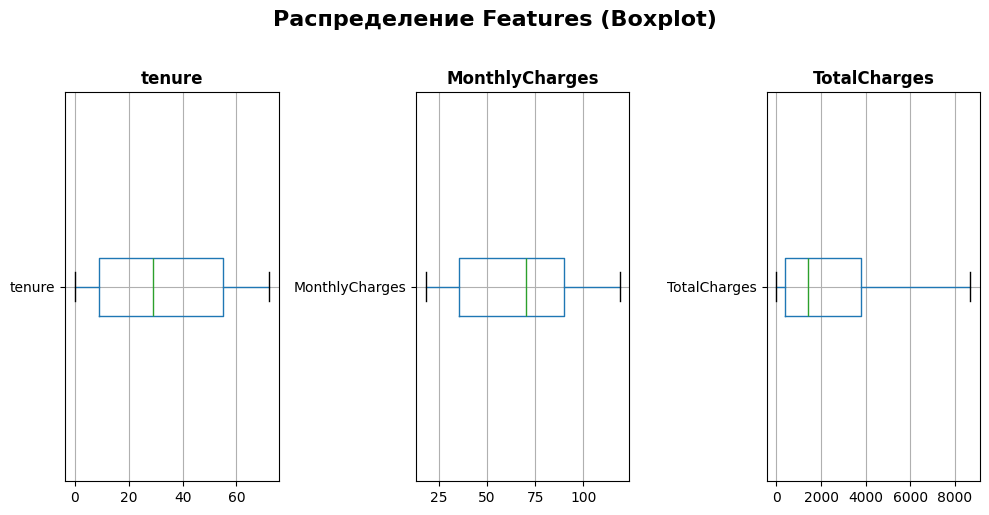

In [213]:
# features для анализа выбросов
features = ['tenure','MonthlyCharges','TotalCharges']

# Преобразование TotalCharges в числовой тип
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Boxplot для features
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
axes = axes.flatten()

for idx, col in enumerate(features):
    ax = axes[idx]
    df.boxplot(column=col, ax=ax, vert=False)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel('')

plt.suptitle('Распределение Features (Boxplot)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Анализ выбросов:**

| Признак | Выбросы | Интерпретация |
|---------|---------|---------------|
| **tenure** | Отсутствуют | - |
| **MonthlyCharges** | Отсутствуют | - |
| **TotalCharges** | Отсутствуют | - |

## 4.3. Проверка аномалий

In [214]:
# Есть ли MonthlyCharges с нулевым значением?

zero_MonthlyCharges = df[df['MonthlyCharges'] == 0]
print(f" Нулевых значений месячной оплаты: {len(zero_MonthlyCharges)}")

if len(zero_MonthlyCharges) > 0:
    print("\nПримеры:")
    display(zero_MonthlyCharges)

 Нулевых значений месячной оплаты: 0


**Вывод**: все абоненты вносят плату

In [227]:
# проверка гипотезы: если у абонента много подключенных услуг, но при этом низкая ежемесячная оплата, то он уже был удержан

services = [
    'PhoneService',
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies'
]


for col in services:
    if col == 'InternetService':
        df[col] = df[col].apply(lambda x: 0 if x == 'No' else 1)
    else:
        df[col] = df[col].apply(lambda x: 1 if x == 'Yes' else 0)


df['NumServices'] = df[services].sum(axis=1)


df['PricePerService'] = df['MonthlyCharges'] / df['NumServices']


print(df[[
    'MonthlyCharges', 'NumServices', 'PricePerService',
    'PhoneService', 'InternetService', 'StreamingTV'
]].head())


low_price_clients = df.query("PricePerService < 10")
high_price_clients = df.query("PricePerService > 40")


print("\nКлиенты с очень низкой ценой за услугу (<$10):")
print(low_price_clients[['customerID', 'MonthlyCharges', 'NumServices', 'PricePerService']])

print("\nКлиенты с очень высокой ценой за услугу (>$40):")
print(high_price_clients[['customerID', 'MonthlyCharges', 'NumServices', 'PricePerService']])

   MonthlyCharges  NumServices  PricePerService  PhoneService  \
0           29.85            1            29.85             0   
1           56.95            1            56.95             0   
2           53.85            1            53.85             0   
3           42.30            1            42.30             0   
4           70.70            1            70.70             0   

   InternetService  StreamingTV  
0                1            0  
1                1            0  
2                1            0  
3                1            0  
4                1            0  

Клиенты с очень низкой ценой за услугу (<$10):
Empty DataFrame
Columns: [customerID, MonthlyCharges, NumServices, PricePerService]
Index: []

Клиенты с очень высокой ценой за услугу (>$40):
      customerID  MonthlyCharges  NumServices  PricePerService
1     5575-GNVDE           56.95            1            56.95
2     3668-QPYBK           53.85            1            53.85
3     7795-CFOCW         

**Вывод**: 5205 неудержанных абонента

## 4.4. Анализ дубликатов

In [216]:
# Дубликаты по customerID
customer_duplicates = df.duplicated(subset=['customerID']).sum()
print(f" Дубликатов customerID: {customer_duplicates:,} ({customer_duplicates/len(df)*100:.2f}%)")

 Дубликатов customerID: 0 (0.00%)


# Одномерный анализ

### 5.1 Целевая переменная Churn

Сначала оцениваем доли ушедших и оставшихся клиентов. В исходных данных 5174 клиента не ушли, значит отток составляет около 26,5% (1869 из 7043). Классы умеренно несбалансированы: при построении модели accuracy сама по себе будет недостаточной метрикой.

,Клиентов,"Доля, %"
Churn,,
No,5174,73.46
Yes,1869,26.54


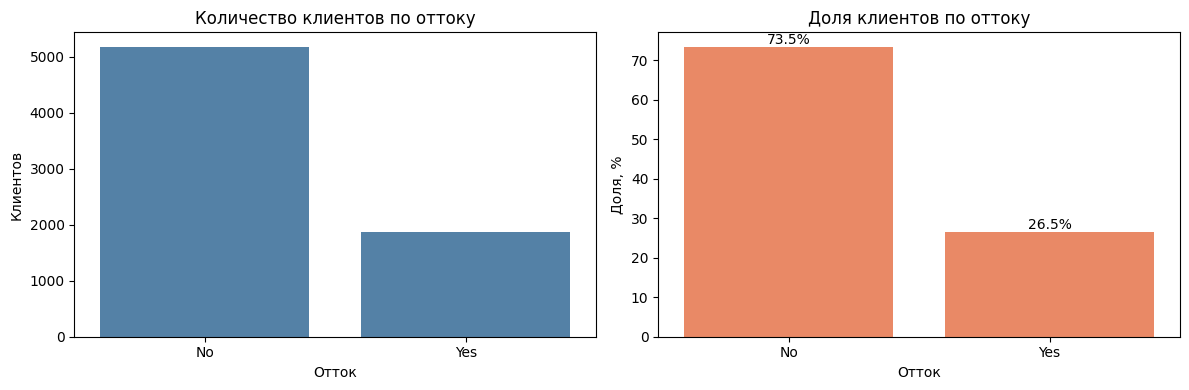

In [217]:
df_eda = df_before_substitute.copy(deep=True)

total_text = df_eda["TotalCharges"].astype("string").str.strip()
blank_total = total_text.eq("")
df_eda["TotalCharges"] = pd.to_numeric(
    total_text.mask(blank_total),
    errors="coerce"
)
df_eda.loc[blank_total & df_eda["tenure"].eq(0), "TotalCharges"] = 0

df_eda["ChurnFlag"] = df_eda["Churn"].map({"No": 0, "Yes": 1})
if df_eda["ChurnFlag"].isna().any():
    raise ValueError("В Churn обнаружены неизвестные категории")

churn_counts = df_eda["Churn"].value_counts().reindex(
    ["No", "Yes"], fill_value=0
)
churn_share = (
    df_eda["Churn"]
    .value_counts(normalize=True)
    .reindex(["No", "Yes"], fill_value=0)
    .mul(100)
)

display(pd.DataFrame({
    "Клиентов": churn_counts,
    "Доля, %": churn_share.round(2)
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df_eda, x="Churn", order=["No", "Yes"],
    ax=axes[0], color="steelblue"
)
axes[0].set(
    title="Количество клиентов по оттоку",
    xlabel="Отток", ylabel="Клиентов"
)

sns.barplot(
    x=churn_share.index, y=churn_share.values,
    order=["No", "Yes"], ax=axes[1], color="coral"
)
axes[1].set(
    title="Доля клиентов по оттоку",
    xlabel="Отток", ylabel="Доля, %"
)

for bar in axes[1].patches:
    axes[1].annotate(
        f"{bar.get_height():.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center", va="bottom"
    )

plt.tight_layout()
plt.show()

**Вывод:** отток — не редкое событие: уходит примерно каждый четвёртый клиент. В последующем анализе сравниваем именно долю `Churn = Yes` внутри сегментов, а не только число строк: сегменты разного размера нельзя корректно ранжировать по абсолютным количествам.

### 5.2 Числовые признаки

`tenure` — срок обслуживания в месяцах, `MonthlyCharges` — ежемесячный платёж, `TotalCharges` — накопленные платежи. Для каждого признака смотрим форму распределения, медиану и возможные крайние значения.

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.79447,0.0,398.55,1394.55,3786.6,8684.8


Пропуски после преобразования TotalCharges:


,Пропусков
tenure,0
MonthlyCharges,0
TotalCharges,0


Нулевые значения:


,Нулей
tenure,11
MonthlyCharges,0
TotalCharges,11


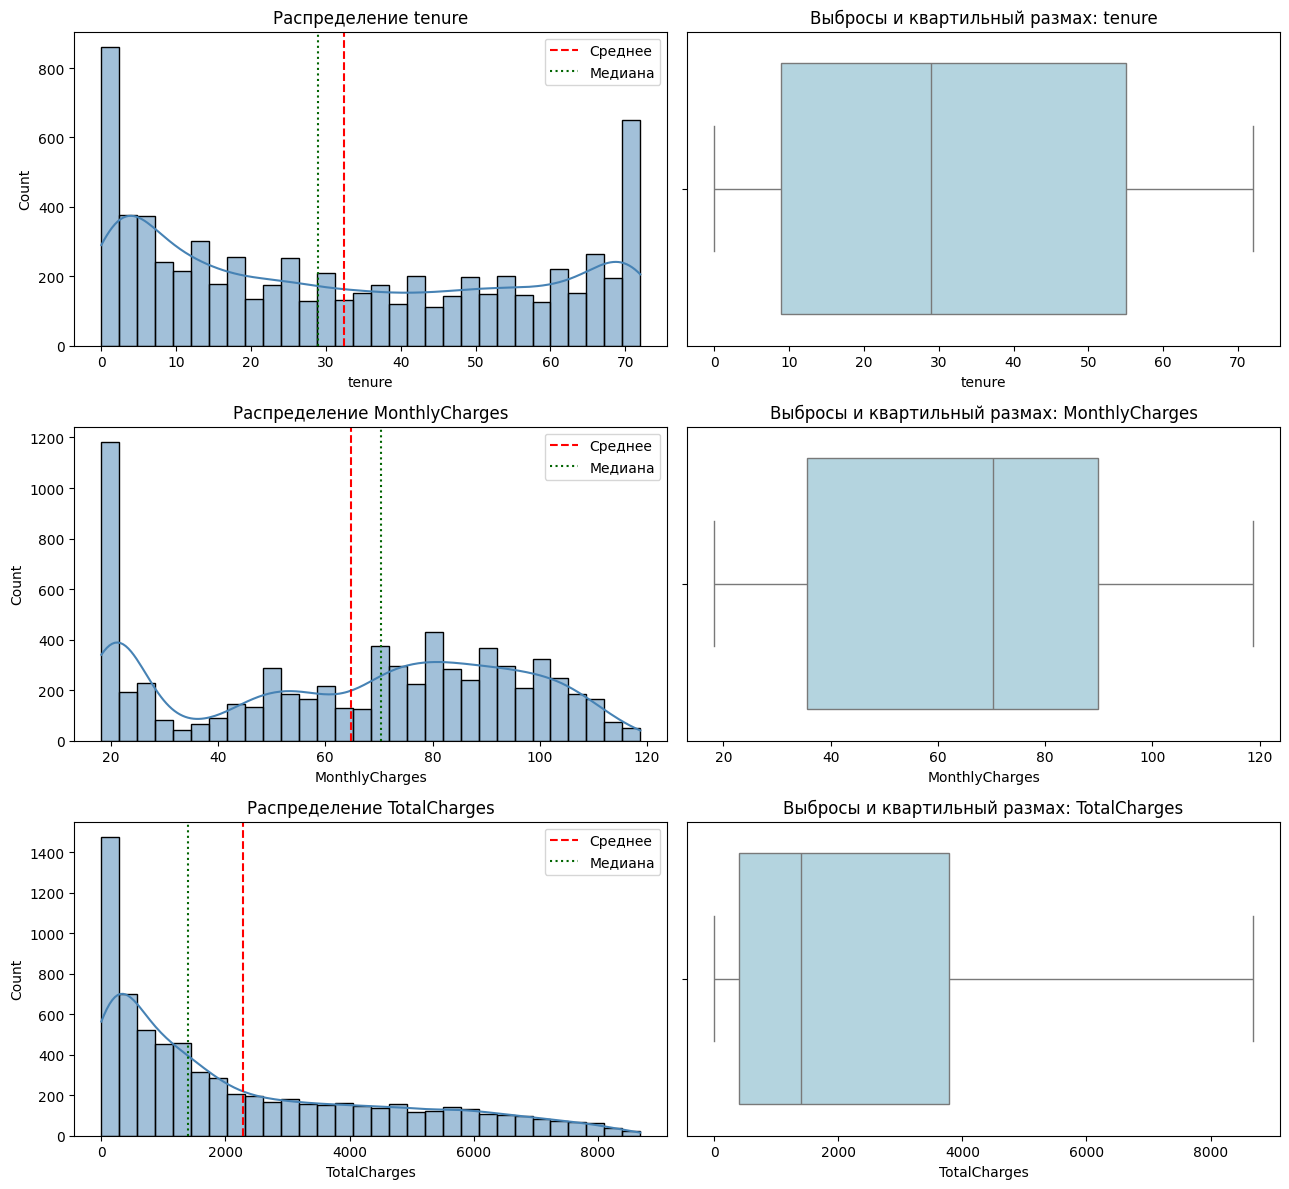

In [218]:
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
display(df_eda[numeric_features].describe().T.round(2))
print('Пропуски после преобразования TotalCharges:')
display(df_eda[numeric_features].isna().sum().rename('Пропусков').to_frame())
print('Нулевые значения:')
display((df_eda[numeric_features].eq(0)).sum().rename('Нулей').to_frame())

fig, axes = plt.subplots(len(numeric_features), 2, figsize=(13, 12))
for row, col in enumerate(numeric_features):
    sns.histplot(df_eda[col].dropna(), bins=30, kde=True, ax=axes[row, 0], color='steelblue')
    axes[row, 0].axvline(df_eda[col].mean(), color='red', linestyle='--', label='Среднее')
    axes[row, 0].axvline(df_eda[col].median(), color='darkgreen', linestyle=':', label='Медиана')
    axes[row, 0].set(title=f'Распределение {col}', xlabel=col)
    axes[row, 0].legend()
    sns.boxplot(x=df_eda[col], ax=axes[row, 1], color='lightblue')
    axes[row, 1].set(title=f'Выбросы и квартильный размах: {col}', xlabel=col)
plt.tight_layout()
plt.show()

**Выводы по форме распределений:** `tenure` имеет заметную концентрацию у новых клиентов и у клиентов с длительным сроком обслуживания; это признак с потенциально сильной связью с оттоком. `TotalCharges` обычно имеет правый хвост, поскольку растёт вместе со сроком обслуживания и ежемесячным платежом. Высокие значения на boxplot не следует автоматически удалять: они могут отражать длительное обслуживание или дорогой тариф. Нулевой `tenure` и пропуски `TotalCharges` нужно проверить совместно — у нового клиента накопленная сумма может быть пустой из-за особенностей выгрузки.

### 5.3 Категориальные признаки

Количество объектов в категории описывает состав выборки, а не риск оттока. Поэтому рядом с частотами считаем churn rate внутри категории.


gender:


,Клиентов,Ушли,Отток_pct
gender,,,
Female,3488,939,26.9
Male,3555,930,26.2



SeniorCitizen:


,Клиентов,Ушли,Отток_pct
SeniorCitizen,,,
1,1142,476,41.7
0,5901,1393,23.6



Partner:


,Клиентов,Ушли,Отток_pct
Partner,,,
No,3641,1200,33.0
Yes,3402,669,19.7


... (22 outputs left out)


PaperlessBilling:


,Клиентов,Ушли,Отток_pct
PaperlessBilling,,,
Yes,4171,1400,33.6
No,2872,469,16.3



PaymentMethod:


,Клиентов,Ушли,Отток_pct
PaymentMethod,,,
Electronic check,2365,1071,45.3
Mailed check,1612,308,19.1
Bank transfer (automatic),1544,258,16.7
Credit card (automatic),1522,232,15.2


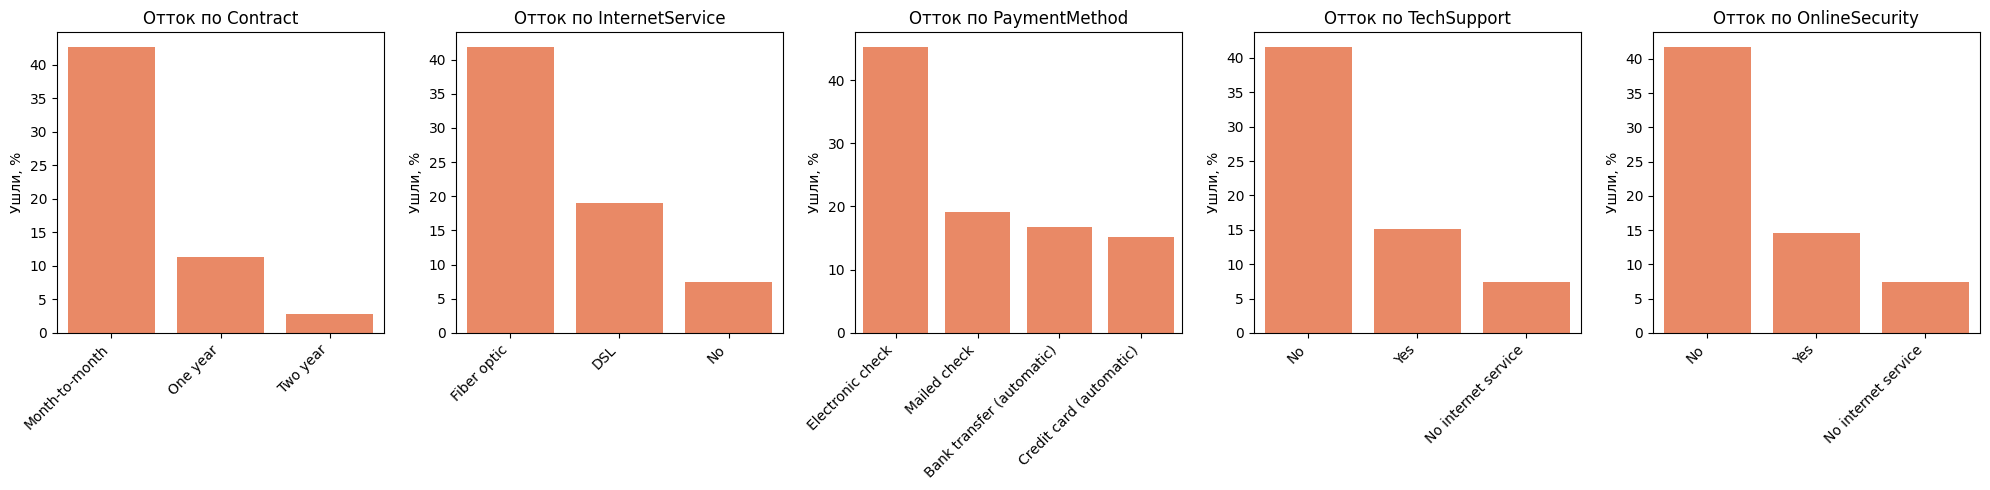

In [219]:
categorical_features = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService',
    'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]

for col in categorical_features:
    print(f'\n{col}:')
    summary = (df_eda.groupby(col, dropna=False, observed=False)
               .agg(Клиентов=('ChurnFlag', 'size'),
                    Ушли=('ChurnFlag', 'sum'),
                    Отток_pct=('ChurnFlag', 'mean'))
               .sort_values('Отток_pct', ascending=False))
    summary['Отток_pct'] = (summary['Отток_pct'] * 100).round(1)
    display(summary)

focus_categories = ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport', 'OnlineSecurity']
fig, axes = plt.subplots(1, len(focus_categories), figsize=(20, 5))
for ax, col in zip(axes, focus_categories):
    rates = (df_eda.groupby(col, observed=False)['ChurnFlag'].mean()
             .mul(100).sort_values(ascending=False))
    sns.barplot(x=rates.index, y=rates.values, ax=ax, color='coral')
    ax.set_title(f'Отток по {col}')
    ax.set_xlabel('')
    ax.set_ylabel('Ушли, %')
    ax.tick_params(axis='x', rotation=45)
    for label in ax.get_xticklabels():
        label.set_ha('right')
plt.tight_layout()
plt.show()

**Ожидаемый содержательный результат:** самый заметный сегментный разрыв обычно виден для `Contract`: у клиентов с помесячным договором доля оттока намного выше, чем у клиентов с годовыми и двухлетними договорами. Повышенный отток также часто наблюдается у клиентов с оптоволоконным интернетом, электронным чеком и без `TechSupport`/`OnlineSecurity`. Это ассоциации в наблюдательных данных, а не доказательство причинности. Категории `No internet service` и `No phone service` — отдельные осмысленные значения, не пропуски.

# Многомерный анализ

## 6.1 Связи числовых признаков и оттока

Сравниваем распределения числовых показателей между ушедшими и оставшимися клиентами. Корреляция Спирмена полезна как оценка монотонных связей и менее чувствительна к форме распределения, чем обычная линейная корреляция Пирсона.

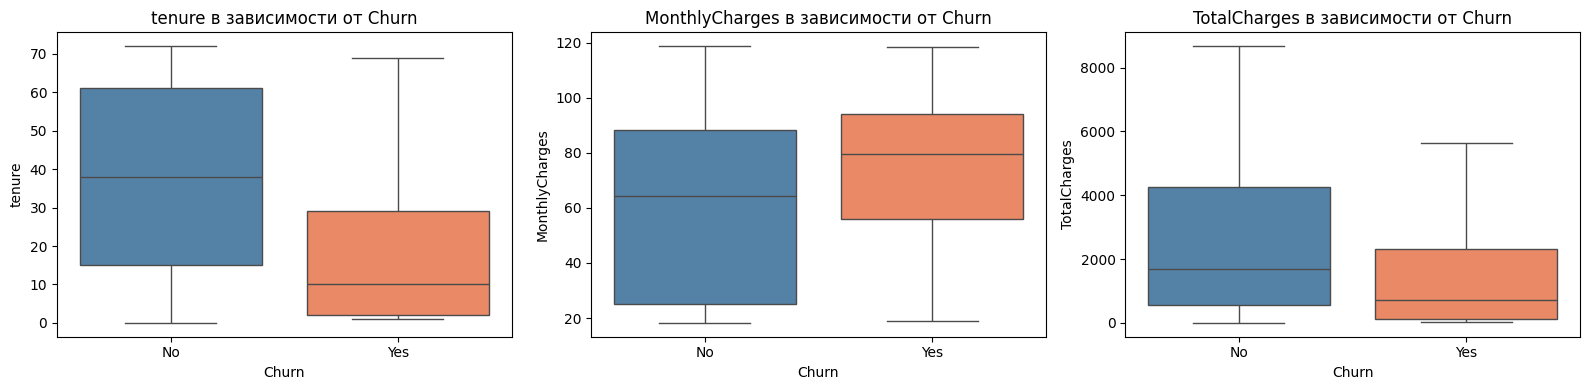

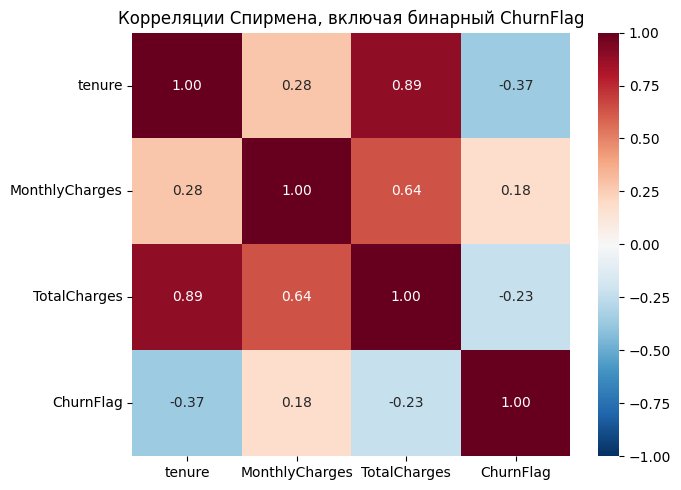

In [220]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, numeric_features):
    sns.boxplot(data=df_eda, x='Churn', y=col,
                order=['No', 'Yes'], hue='Churn', hue_order=['No', 'Yes'],
                ax=ax, showfliers=False,
                palette={'No': 'steelblue', 'Yes': 'coral'},
                legend=False)
    ax.set_title(f'{col} в зависимости от Churn')
plt.tight_layout()
plt.show()

spearman = df_eda[['tenure', 'MonthlyCharges', 'TotalCharges', 'ChurnFlag']].corr(method='spearman')
plt.figure(figsize=(7, 5))
sns.heatmap(spearman, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Корреляции Спирмена, включая бинарный ChurnFlag')
plt.tight_layout()
plt.show()

**Интерпретация:** наиболее ожидаемый паттерн — меньший `tenure` среди ушедших клиентов. `TotalCharges` нельзя трактовать отдельно от `tenure`: накопленная сумма по смыслу зависит от срока обслуживания. Поэтому для удержания клиентов полезнее изучать сочетания короткого срока, типа договора, тарифа и ежемесячного платежа, а не делать вывод по одной корреляции.

## 6.2 Риск оттока по сроку и ежемесячному платежу

Группировка показывает нелинейность и сегменты риска. Квантили `MonthlyCharges` используются, чтобы получить сопоставимые по размеру группы.

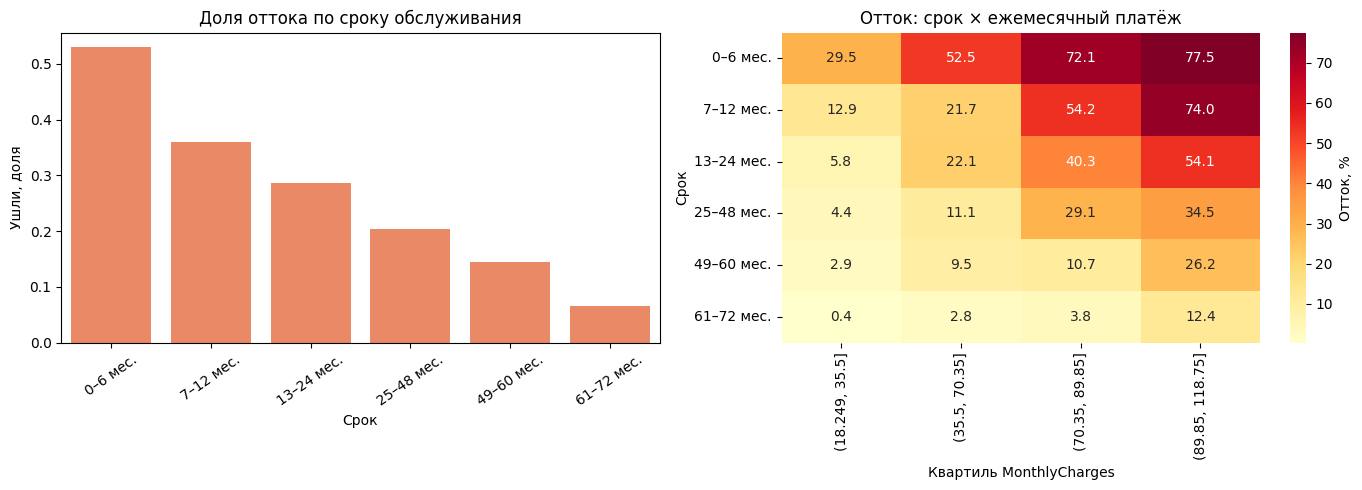

In [221]:
df_eda['TenureGroup'] = pd.cut(
    df_eda['tenure'], bins=[-1, 6, 12, 24, 48, 60, 72],
    labels=['0–6 мес.', '7–12 мес.', '13–24 мес.', '25–48 мес.', '49–60 мес.', '61–72 мес.'],
    include_lowest=True
)
df_eda['MonthlyChargeGroup'] = pd.qcut(
    df_eda['MonthlyCharges'], q=4, duplicates='drop'
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tenure_risk = (df_eda.groupby('TenureGroup', observed=False)['ChurnFlag']
               .agg(['mean', 'size']).reset_index())
sns.barplot(data=tenure_risk, x='TenureGroup', y='mean', ax=axes[0], color='coral')
axes[0].set(title='Доля оттока по сроку обслуживания', xlabel='Срок', ylabel='Ушли, доля')
axes[0].tick_params(axis='x', rotation=35)

charge_tenure = (df_eda.pivot_table(index='TenureGroup', columns='MonthlyChargeGroup',
                                    values='ChurnFlag', aggfunc='mean', observed=False) * 100)
sns.heatmap(charge_tenure, annot=True, fmt='.1f', cmap='YlOrRd', ax=axes[1], cbar_kws={'label': 'Отток, %'})
axes[1].set(title='Отток: срок × ежемесячный платёж', xlabel='Квартиль MonthlyCharges', ylabel='Срок')
plt.tight_layout()
plt.show()

**Выводы:** в этом наборе данных основной ожидаемый паттерн — самый высокий отток у клиентов с коротким сроком обслуживания; по мере роста `tenure` риск обычно снижается. Тепловая карта помогает проверить, усиливается ли отток среди клиентов с высокими `MonthlyCharges` внутри каждой группы стажа. Если цветовые различия по квартилям платежа слабее, чем по стажу, то стаж разделяет клиентов заметнее, чем сама сумма ежемесячного платежа.

## 6.3 Сочетания категориальных факторов

Проверяем совместное распределение договора и интернет-услуги. В таблице выводим долю оттока внутри каждой комбинации; малые сегменты стоит трактовать осторожно.

Размеры сегментов:


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,1223,2128,524
One year,570,539,364
Two year,628,429,638


Доля Churn = Yes внутри сочетания Contract × InternetService, %:


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.2,54.6,18.9
One year,9.3,19.3,2.5
Two year,1.9,7.2,0.8


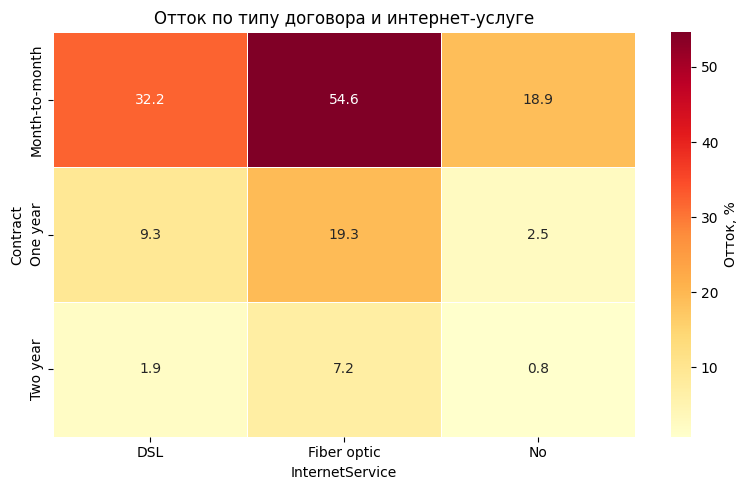

In [222]:
segment = (df_eda.pivot_table(index='Contract', columns='InternetService',
                              values='ChurnFlag', aggfunc='mean', observed=False) * 100)
segment_n = pd.crosstab(df_eda['Contract'], df_eda['InternetService'])
print('Размеры сегментов:')
display(segment_n)
print('Доля Churn = Yes внутри сочетания Contract × InternetService, %:')
display(segment.round(1))

plt.figure(figsize=(8, 5))
sns.heatmap(segment, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=.5,
            cbar_kws={'label': 'Отток, %'})
plt.title('Отток по типу договора и интернет-услуге')
plt.tight_layout()
plt.show()

**Выводы:** наиболее заметное различие наблюдается между типами договора: отток выше у клиентов с помесячным договором и ниже у клиентов с контрактом на год или два. По типу интернета отток обычно выше у пользователей оптоволокна, чем у клиентов без интернета; сравнение `DSL` с оптоволокном показывает, меняется ли разрыв в зависимости от срока договора. Самые высокие доли часто наблюдаются в сочетании помесячного договора и оптоволокна, а длинный договор связан с более низким оттоком при разных типах интернета.

Для оценки силы связи между категориальными признаками используем коэффициент V Крамера. Он принимает значения от 0 до 1: чем ближе значение к 0, тем слабее связь, а чем ближе к 1 — тем сильнее. Коэффициент позволяет сравнивать пары признаков, например тип договора и наличие оттока. Сам по себе V Крамера не показывает направление связи и не доказывает причинно-следственную зависимость, поэтому для интерпретации отдельных групп дополнительно рассматривались доли оттока.

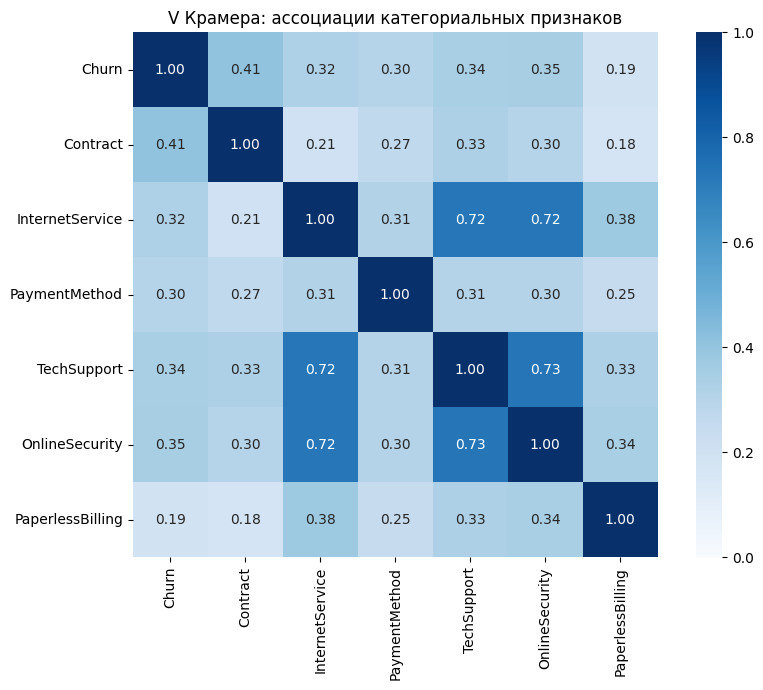

In [223]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if table.empty or min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    return np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))

assoc_features = ['Churn', 'Contract', 'InternetService', 'PaymentMethod',
                  'TechSupport', 'OnlineSecurity', 'PaperlessBilling']
cramers = pd.DataFrame(index=assoc_features, columns=assoc_features, dtype=float)
for col1 in assoc_features:
    for col2 in assoc_features:
        cramers.loc[col1, col2] = cramers_v(df_eda[col1], df_eda[col2])

plt.figure(figsize=(9, 7))
sns.heatmap(cramers, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, square=True)
plt.title('V Крамера: ассоциации категориальных признаков')
plt.tight_layout()
plt.show()

По матрице V Крамера наиболее сильная связь с оттоком наблюдается у типа договора (`Contract`, V = 0,41). Далее следуют наличие онлайн-защиты (`OnlineSecurity`, 0,35), технической поддержки (`TechSupport`, 0,34), тип интернет-подключения (`InternetService`, 0,32) и способ оплаты (`PaymentMethod`, 0,30). Связь `PaperlessBilling` с оттоком слабее среди рассмотренных признаков (V = 0,19).

Между некоторыми услугами также обнаружена сильная ассоциация: V составляет 0,72 для пар `InternetService`—`TechSupport` и `InternetService`—`OnlineSecurity`, а для `TechSupport`—`OnlineSecurity` — 0,73. Значит, эти признаки могут нести частично совпадающую информацию.

# Сегментный анализ

## 7.1 Отток по числу базовых подключённых услуг

,NumBasicServices,Клиентов,Ушли,Доля_оттока_pct
0,1,1923,219,11.4
1,2,2698,900,33.4
2,3,2422,750,31.0


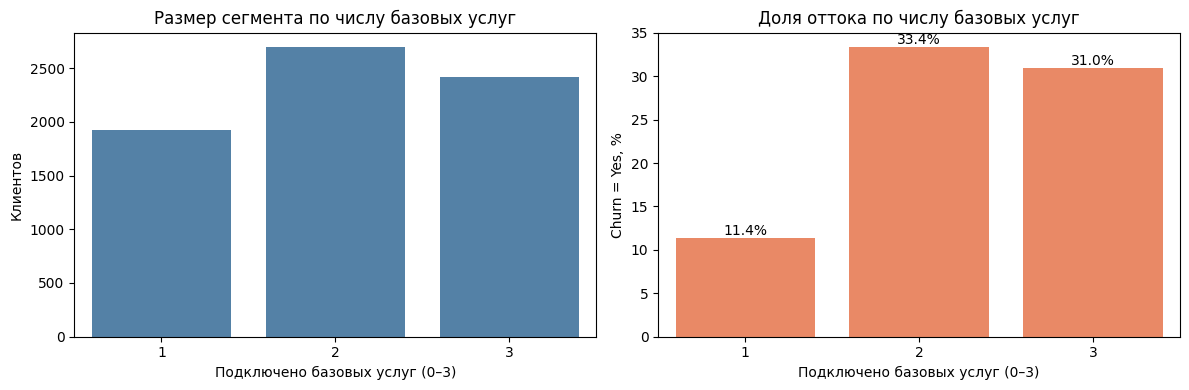

In [224]:
df_eda["HasInternet"] = df_eda["InternetService"].isin(
    ["DSL", "Fiber optic"]
).astype(int)
df_eda["HasPhone"] = df_eda["PhoneService"].eq("Yes").astype(int)
df_eda["HasTV"] = df_eda["StreamingTV"].eq("Yes").astype(int)

base_service_flags = ["HasInternet", "HasPhone", "HasTV"]
df_eda["NumBasicServices"] = df_eda[base_service_flags].sum(axis=1)
basic_service_summary = (
    df_eda.groupby('NumBasicServices', observed=False)
    .agg(
        Клиентов=('ChurnFlag', 'size'),
        Ушли=('ChurnFlag', 'sum'),
        Доля_оттока=('ChurnFlag', 'mean')
    )
    .reset_index()
)

basic_service_summary = (
    df_eda.groupby('NumBasicServices', observed=False)
    .agg(
        Клиентов=('ChurnFlag', 'size'),
        Ушли=('ChurnFlag', 'sum'),
        Доля_оттока=('ChurnFlag', 'mean')
    )
    .reset_index()
)
basic_service_summary['Доля_оттока_pct'] = basic_service_summary['Доля_оттока'] * 100
display(basic_service_summary.drop(columns='Доля_оттока').round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=basic_service_summary, x='NumBasicServices', y='Клиентов',
            ax=axes[0], color='steelblue')
axes[0].set(title='Размер сегмента по числу базовых услуг',
            xlabel='Подключено базовых услуг (0–3)', ylabel='Клиентов')

sns.barplot(data=basic_service_summary, x='NumBasicServices', y='Доля_оттока_pct',
            ax=axes[1], color='coral')
axes[1].set(title='Доля оттока по числу базовых услуг',
            xlabel='Подключено базовых услуг (0–3)', ylabel='Churn = Yes, %')
for bar in axes[1].patches:
    axes[1].annotate(f'{bar.get_height():.1f}%',
                     (bar.get_x() + bar.get_width()/2, bar.get_height()),
                     ha='center', va='bottom')
plt.tight_layout()
plt.show()

## 7.2 Социально-демографические сегменты оттока


Отток по признаку «Пол»:


,gender,Клиентов,Ушли,Доля_оттока_pct
0,Female,3488,939,26.9
1,Male,3555,930,26.2



Отток по признаку «Пожилой клиент»:


,SeniorCitizenGroup,Клиентов,Ушли,Доля_оттока_pct
0,No,5901,1393,23.6
1,Yes,1142,476,41.7



Отток по признаку «Есть партнёр»:


,Partner,Клиентов,Ушли,Доля_оттока_pct
0,No,3641,1200,33.0
1,Yes,3402,669,19.7



Отток по признаку «Есть иждивенцы»:


,Dependents,Клиентов,Ушли,Доля_оттока_pct
0,No,4933,1543,31.3
1,Yes,2110,326,15.5


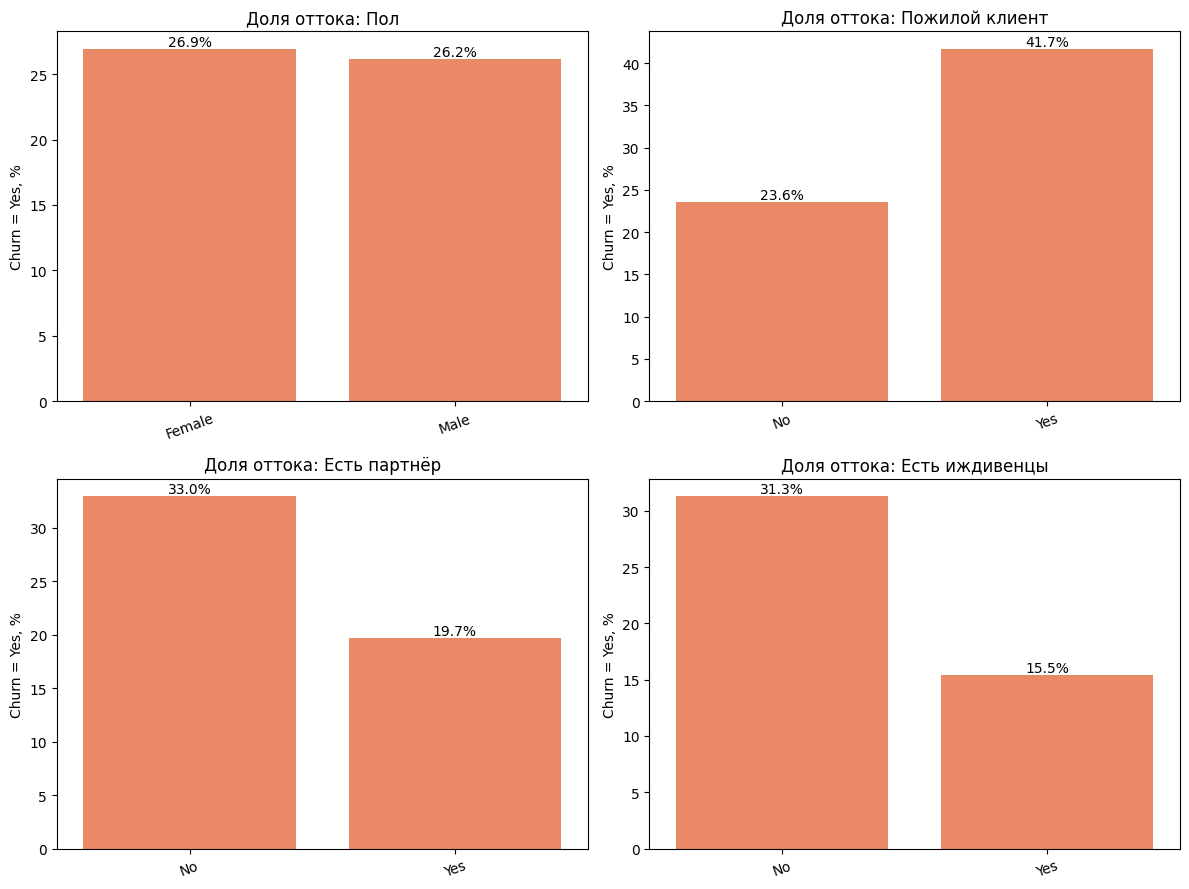

In [225]:
df_eda['SeniorCitizenGroup'] = df_eda['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
demo_features = ['gender', 'SeniorCitizenGroup', 'Partner', 'Dependents']
demo_labels = {
    'gender': 'Пол',
    'SeniorCitizenGroup': 'Пожилой клиент',
    'Partner': 'Есть партнёр',
    'Dependents': 'Есть иждивенцы'
}

demo_summaries = {}
for col in demo_features:
    summary = (
        df_eda.groupby(col, dropna=False, observed=False)
        .agg(
            Клиентов=('ChurnFlag', 'size'),
            Ушли=('ChurnFlag', 'sum'),
            Доля_оттока=('ChurnFlag', 'mean')
        )
        .reset_index()
    )
    summary['Доля_оттока_pct'] = summary['Доля_оттока'] * 100
    demo_summaries[col] = summary
    print(f"\nОтток по признаку «{demo_labels[col]}»:")
    display(summary.drop(columns='Доля_оттока').round(1))

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, col in zip(axes.flat, demo_features):
    summary = demo_summaries[col]
    sns.barplot(data=summary, x=col, y='Доля_оттока_pct', ax=ax, color='coral')
    ax.set(title=f"Доля оттока: {demo_labels[col]}", xlabel='', ylabel='Churn = Yes, %')
    ax.tick_params(axis='x', rotation=20)
    for bar in ax.patches:
        ax.annotate(f'{bar.get_height():.1f}%',
                    (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    ha='center', va='bottom')
plt.tight_layout()
plt.show()

## 7.3 Сочетания сегментов

Количество клиентов в сочетаниях Partner × Dependents:


Dependents,No,Yes
Partner,,
No,3280,361
Yes,1653,1749


Доля оттока в сочетаниях Partner × Dependents, %:


Dependents,No,Yes
Partner,,
No,34.2,21.3
Yes,25.4,14.2


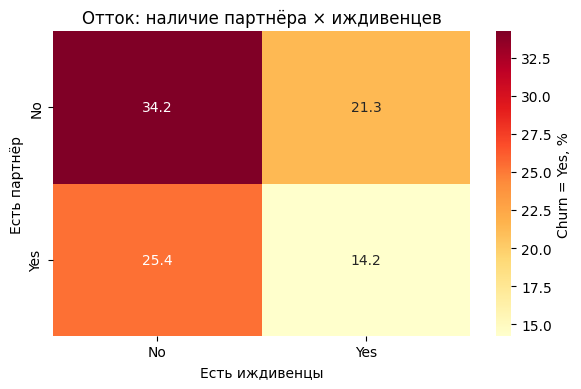

In [226]:
demo_joint_counts = pd.crosstab(df_eda['Partner'], df_eda['Dependents'])
demo_joint_churn = (
    df_eda.pivot_table(index='Partner', columns='Dependents', values='ChurnFlag',
                       aggfunc='mean', observed=False) * 100
)
print('Количество клиентов в сочетаниях Partner × Dependents:')
display(demo_joint_counts)
print('Доля оттока в сочетаниях Partner × Dependents, %:')
display(demo_joint_churn.round(1))

plt.figure(figsize=(6, 4))
sns.heatmap(demo_joint_churn, annot=True, fmt='.1f', cmap='YlOrRd',
            cbar_kws={'label': 'Churn = Yes, %'})
plt.title('Отток: наличие партнёра × иждивенцев')
plt.xlabel('Есть иждивенцы')
plt.ylabel('Есть партнёр')
plt.tight_layout()
plt.show()